# Predição de risco de AVC: modelagem, avaliação e explicabilidade

**Projeto de Machine Learning — APS 2**

**Docente:** Humberto Sandman

**Equipe:**

- Emily Britto — *emilybg@al.insper.edu.br*
- Gabriel Chaves Aguiar — *gabrielca5@al.insper.edu.br*

**Data de entrega:** 30/10/2026

**Referências bibliográficas:** Seção 5, ao final do notebook.

---

Continuação da APS1 (`aps_machine_learning.ipynb`), onde fizemos a análise
exploratória do dataset de AVC e construímos o pipeline de pré-processamento.
Aqui partimos para a modelagem: seleção de modelos, ajuste de hiperparâmetros,
avaliação no conjunto de teste e interpretação.

## Checklist da rubrica (APS 2)

### 1. Seleção e implementação dos modelos

- [OK] Mesmo pipeline da APS1 com 3 modelos distintos: Dummy, linear com regularização e ensemble de árvores (Seção 1.1)
- [OK] Uma métrica de desempenho (PR-AUC) reportada para os 3 modelos (Seção 1.1)
- [OK] Seleção de hiperparâmetros com `GridSearchCV` para o linear e o ensemble, com a mesma métrica (Seção 1.2)
- [OK] Proposta e implementação de uma mudança no pipeline: indicador de ausência do `bmi` (Seção 1.3)
- [OK] Impacto da mudança no melhor modelo, com a mesma métrica, mesma validação e nova seleção de hiperparâmetros (Seção 1.3)
- [OK] Curvas de aprendizado do melhor modelo final (Seção 1.4)

### 2. Avaliação do melhor modelo no conjunto de teste (classificação)

- [OK] Accuracy, Precision, Recall e F1-score (Seção 2)
- [OK] Matriz de confusão, com falsos positivos e falsos negativos (Seção 2)
- [OK] Curva ROC e ROC-AUC (Seção 2)

### 3. Interpretação e explicabilidade

- [OK] Modelo linear: 3 features com coeficientes de maior magnitude (Seção 3.1)
- [OK] Modelo ensemble: 3 features de maior importância (Seção 3.2)
- [OK] SHAP no melhor modelo: importância global e 3 predições individuais explicadas (Seção 3.3)

### 4. Discussão crítica

- [OK] Duas limitações do melhor modelo, não apresentadas antes (Seção 4.1)
- [OK] Duas limitações dos dados, não apresentadas antes (Seção 4.2)
- [OK] Duas ações para operacionalização e manutenção (Seção 4.3)

### Instruções adicionais

- [OK] Figuras e decisões justificadas e analisadas (blocos **Leitura** / **Análise** após cada resultado)
- [OK] Visualizações com títulos, rótulos e legendas
- [OK] Código organizado e comentado
- [OK] Discussão crítica fundamentada com referências bibliográficas (Seção 5)
- [OK] Python com Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn e shap (Seaborn no gráfico de coeficientes da Seção 3.1)
- [OK] Identificação dos membros, título, data de entrega e referências

## Setup: o pipeline da APS1

Repetimos o carregamento, a divisão treino/teste e o pré-processador da APS1
para que este notebook seja autocontido. A divisão usa `stratify=y` e o mesmo
`random_state=42`, então o conjunto de teste é exatamente o mesmo da APS1.

A única diferença em relação à APS1 é `verbose_feature_names_out=False`, que só
remove o prefixo do transformador nos nomes das features (`age` em vez de
`numericas__age`) e deixa os gráficos de interpretação legíveis.

In [1]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
df = pd.read_csv(f"{path}/healthcare-dataset-stroke-data.csv")

X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

colunas_numericas = ["age", "avg_glucose_level", "bmi"]
colunas_categoricas = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status",
]
colunas_binarias = ["hypertension", "heart_disease"]


def constroi_pre_processador(add_indicator=False):
    # numéricas: mediana (robusta aos outliers de glicose e IMC) + padronização
    pipeline_numerico = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median", add_indicator=add_indicator)),
            ("scaler", StandardScaler()),
        ]
    )

    return ColumnTransformer(
        [
            ("numericas", pipeline_numerico, colunas_numericas),
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
            ("binarias", "passthrough", colunas_binarias),
        ],
        verbose_feature_names_out=False,
    )


def monta_pipeline(classificador, add_indicator=False):
    # o pré-processador fica dentro do pipeline para ser ajustado só no fold de treino
    return Pipeline(
        [
            ("pre_processamento", constroi_pre_processador(add_indicator)),
            ("classificador", classificador),
        ]
    )


print(f"Treino: {len(X_train)} observações | Teste: {len(X_test)} observações")
print(f"Prevalência de AVC no treino: {y_train.mean():.2%}")

C:\Users\gabri\Documents\faculdade\s4\ml\projeto-machine-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Treino: 4088 observações | Teste: 1022 observações
Prevalência de AVC no treino: 4.87%


## Escolha da métrica de desempenho

Escolhemos a **PR-AUC** (*average precision*) como métrica principal.

A justificativa vem do que encontramos na APS1: apenas **4,87%** dos pacientes
tiveram AVC. Nesse cenário:

- **Accuracy é inútil.** Um modelo que responde "sem AVC" para todo mundo acerta
  95,1% das vezes e não detecta um único caso.
- **ROC-AUC é otimista.** A taxa de falsos positivos divide os alarmes falsos
  por todos os negativos, que são 95% da base. Um modelo pode ter taxa de falsos
  positivos baixa e, mesmo assim, gerar muito mais alarmes falsos do que acertos.
- **PR-AUC enxerga o problema.** Precision e recall ignoram os verdadeiros
  negativos. A linha de base da PR-AUC é a própria prevalência (**0,0487**),
  então qualquer valor acima disso é ganho real sobre o acaso.

Usamos a PR-AUC em **todas** as etapas: comparação dos modelos base, `scoring`
dos `GridSearchCV`, avaliação da mudança no pipeline e curvas de aprendizado.
A validação é sempre `StratifiedKFold(n_splits=5, shuffle=True)`: com 4,87% de
positivos, um fold sem estratificação poderia ficar com pouquíssimos casos.

Na Seção 2 reportamos também Accuracy, Precision, Recall, F1 e ROC-AUC, como
pede o enunciado, mas a escolha do melhor modelo foi feita pela PR-AUC.

In [2]:
from sklearn.model_selection import cross_val_score

METRICA = "average_precision"  # PR-AUC
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Linha de base da PR-AUC (prevalência): {y_train.mean():.4f}")

Linha de base da PR-AUC (prevalência): 0.0487


---

## 1. Seleção e implementação dos modelos

### 1.1 Os três modelos

| Modelo | Papel | Por que este |
|---|---|---|
| `DummyClassifier` | Piso de referência | Prediz respeitando a proporção das classes, sem olhar para as features. Qualquer modelo útil precisa superá-lo. |
| `LogisticRegression` | Linear com regularização | Modelo de referência da APS1. A regularização (L1/L2) controla o overfitting e, no caso da L1, zera coeficientes irrelevantes. |
| `RandomForestClassifier` | Ensemble de árvores | Captura interações e relações não lineares que a regressão logística não alcança. |

Os três entram no **mesmo pipeline**, com o pré-processador da APS1 na frente,
de modo que imputação e padronização são aprendidas apenas no fold de treino de
cada partição da validação cruzada, sem vazamento.

Regressão logística e floresta usam `class_weight="balanced"`, nossa resposta ao
desbalanceamento desde a APS1: o peso de cada classe é inversamente proporcional
à sua frequência, então errar um caso de AVC custa cerca de 20 vezes mais do que
errar um caso negativo.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

modelos = {
    "Dummy": DummyClassifier(strategy="stratified", random_state=42),
    "Regressão Logística": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

scores_base = {
    nome: cross_val_score(
        monta_pipeline(modelo), X_train, y_train, scoring=METRICA, cv=cv, n_jobs=-1
    )
    for nome, modelo in modelos.items()
}

tabela_base = pd.DataFrame(
    {
        "PR-AUC (média)": [s.mean() for s in scores_base.values()],
        "desvio padrão": [s.std() for s in scores_base.values()],
    },
    index=list(scores_base),
)

display(tabela_base.round(4))

,PR-AUC (média),desvio padrão
Dummy,0.0488,0.0004
Regressão Logística,0.1933,0.0389
Random Forest,0.1691,0.0393


**Leitura.** O Dummy fica em ~0,049, exatamente a prevalência, o que confirma
que a métrica está calibrada. Os dois modelos reais ficam entre 0,17 e 0,19,
cerca de **4x acima do acaso**. A regressão logística sai na frente da floresta
na configuração padrão, o que faz sentido: uma floresta sem limite de
profundidade decora o treino, e com 199 casos positivos no treino há pouco sinal
para generalizar.

O desvio padrão entre folds (~0,04) é alto em relação à média. Também é efeito
do desbalanceamento: cada fold de validação tem só ~40 casos positivos, então a
estimativa oscila bastante. É um motivo a mais para não celebrar diferenças
pequenas entre modelos.

### 1.2 Seleção de hiperparâmetros

Usamos `GridSearchCV` com a mesma métrica e a mesma estratégia de validação:

- **Regressão logística:** `C` (força da regularização, em escala log de 0,001 a
  100) e `l1_ratio` (0 = L2, 1 = L1). O solver `liblinear` suporta as duas
  penalidades.
- **Random Forest:** os parâmetros que controlam o quanto a floresta pode
  decorar: `max_depth`, `min_samples_leaf` e `max_features`. Fixamos
  `n_estimators=300`, porque mais árvores não pioram uma floresta, só custam
  tempo.

In [4]:
from sklearn.model_selection import GridSearchCV

grade_logistica = {
    "classificador__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classificador__l1_ratio": [0, 1],
    "classificador__solver": ["liblinear"],
}

busca_logistica = GridSearchCV(
    monta_pipeline(modelos["Regressão Logística"]),
    grade_logistica,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)
busca_logistica.fit(X_train, y_train)

print(f"Regressão Logística | PR-AUC: {busca_logistica.best_score_:.4f}")
print(busca_logistica.best_params_)

Regressão Logística | PR-AUC: 0.1935
{'classificador__C': 1, 'classificador__l1_ratio': 1, 'classificador__solver': 'liblinear'}


In [5]:
grade_floresta = {
    "classificador__n_estimators": [300],
    "classificador__max_depth": [None, 5, 10],
    "classificador__min_samples_leaf": [1, 5, 20],
    "classificador__max_features": ["sqrt", 0.5],
}

busca_floresta = GridSearchCV(
    monta_pipeline(modelos["Random Forest"]),
    grade_floresta,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)
busca_floresta.fit(X_train, y_train)

print(f"Random Forest | PR-AUC: {busca_floresta.best_score_:.4f}")
print(busca_floresta.best_params_)

Random Forest | PR-AUC: 0.2079
{'classificador__max_depth': 10, 'classificador__max_features': 0.5, 'classificador__min_samples_leaf': 20, 'classificador__n_estimators': 300}


In [6]:
comparacao = tabela_base.loc[["Regressão Logística", "Random Forest"], ["PR-AUC (média)"]]
comparacao.columns = ["PR-AUC base"]
comparacao["PR-AUC ajustado"] = [busca_logistica.best_score_, busca_floresta.best_score_]
comparacao["ganho"] = comparacao["PR-AUC ajustado"] - comparacao["PR-AUC base"]

display(comparacao.round(4))

,PR-AUC base,PR-AUC ajustado,ganho
Regressão Logística,0.1933,0.1935,0.0002
Random Forest,0.1691,0.2079,0.0389


**Leitura.** A regressão logística praticamente não se move com o ajuste: o
`C=1` escolhido é o próprio valor padrão, e a troca para L1 só mexe na quarta
casa decimal. Era esperado: o modelo tem poucas features e pouca liberdade para
se ajustar.

A floresta, por outro lado, ganha de forma clara quando é podada
(`max_depth=10`, `min_samples_leaf=20`) e passa à frente da regressão logística.
Confirma o diagnóstico anterior: a floresta padrão estava decorando o treino.

O melhor modelo até aqui é a **Random Forest ajustada**.

### 1.3 Mudança proposta no pipeline: sinalizar o `bmi` ausente

Na APS1 tratamos os 201 valores ausentes de `bmi` (3,93% da base) imputando a
mediana. A imputação preenche o buraco, mas **apaga a informação de que havia um
buraco ali**. A pergunta que não fizemos foi: a ausência em si diz alguma coisa?

Investigamos apenas no conjunto de treino, para que a decisão não use o teste.

In [7]:
treino = X_train.assign(stroke=y_train)
bmi_ausente = treino["bmi"].isna().map({False: "bmi presente", True: "bmi ausente"})

investigacao = treino.groupby(bmi_ausente).agg(
    pacientes=("stroke", "size"),
    casos_avc=("stroke", "sum"),
    taxa_avc=("stroke", "mean"),
    idade_media=("age", "mean"),
)

display(investigacao.round(3))

,pacientes,casos_avc,taxa_avc,idade_media
bmi,,,,
bmi ausente,170,37,0.218,53.329
bmi presente,3918,162,0.041,42.920


**O achado.** Entre os pacientes sem `bmi` registrado, a taxa de AVC é de
**21,8%**, contra **4,1%** entre os que têm a medida, uma
diferença de cerca de **5x**. Esses pacientes também são, em média,
10 anos mais velhos.

A ausência não é aleatória: ela carrega sinal. Uma explicação plausível é que
pacientes em estado grave não tiveram o IMC aferido, e esses são justamente os
mais propensos a ter tido um AVC. Na terminologia de Rubin [1], isso descarta a
hipótese de ausência completamente aleatória (MCAR): a ausência depende de outras
variáveis, como idade e desfecho. Se ela depende também do próprio IMC não
medido (MNAR), estes dados não permitem dizer. Para a modelagem, o que importa é
que a ausência é informativa e não pode ser tratada como ruído.

**A mudança:** ligar `add_indicator=True` no `SimpleImputer` das variáveis
numéricas. O imputer continua preenchendo com a mediana, mas passa a adicionar
uma coluna binária (`missingindicator_bmi`) marcando as linhas imputadas.

Refazemos a seleção de hiperparâmetros com a mesma grade, a mesma métrica e a
mesma validação; o único componente que muda é o pré-processador.

In [8]:
busca_floresta_v2 = GridSearchCV(
    monta_pipeline(modelos["Random Forest"], add_indicator=True),
    grade_floresta,
    scoring=METRICA,
    cv=cv,
    n_jobs=-1,
)
busca_floresta_v2.fit(X_train, y_train)

print(f"Random Forest + indicador de ausência | PR-AUC: {busca_floresta_v2.best_score_:.4f}")
print(busca_floresta_v2.best_params_)

impacto = pd.DataFrame(
    {
        "PR-AUC": [busca_floresta.best_score_, busca_floresta_v2.best_score_],
        "desvio padrão": [
            b.cv_results_["std_test_score"][b.best_index_] for b in (busca_floresta, busca_floresta_v2)
        ],
    },
    index=["pipeline APS1", "pipeline + indicador"],
)
impacto["variação"] = impacto["PR-AUC"] - busca_floresta.best_score_

display(impacto.round(4))

Random Forest + indicador de ausência | PR-AUC: 0.2526
{'classificador__max_depth': 5, 'classificador__max_features': 0.5, 'classificador__min_samples_leaf': 1, 'classificador__n_estimators': 300}


,PR-AUC,desvio padrão,variação
pipeline APS1,0.2079,0.0431,0.0000
pipeline + indicador,0.2526,0.0512,0.0446


**Impacto.** A PR-AUC sobe de **0,2079** para **0,2526**, um ganho de
**+0,045** (cerca de **+21%** em termos relativos). É o maior ganho do trabalho,
maior do que o ajuste de hiperparâmetros dos dois modelos somado.

O ganho é da mesma ordem do desvio padrão entre folds (0,043 sem o indicador e
0,051 com ele): o resultado é promissor, mas não esmagador, e seria preciso repetir a validação com outras
sementes para afirmar algo mais forte.

Os hiperparâmetros ótimos também mudaram (`max_depth` caiu de 10 para 5): com
um preditor mais forte disponível, a floresta precisa de menos profundidade. É
exatamente por isso que refizemos o `GridSearchCV` em vez de reaproveitar os
parâmetros anteriores.

**Melhor modelo final: Random Forest + indicador de ausência.**

In [9]:
melhor_modelo = busca_floresta_v2.best_estimator_

melhor_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre_processamento', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that

### 1.4 Curvas de aprendizado

As curvas mostram como o desempenho evolui conforme aumentamos a quantidade de
dados de treino. Respondem a duas perguntas: o modelo sofre de variância
(overfitting) ou de viés? E coletar mais dados ajudaria?

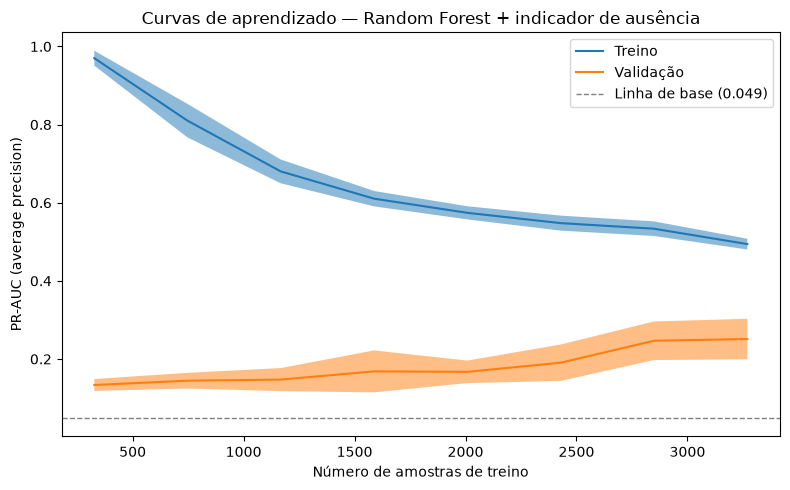

,PR-AUC treino,PR-AUC validação,lacuna
amostras de treino,,,
327,0.970,0.134,0.837
747,0.810,0.145,0.666
1167,0.680,0.147,0.533
1588,0.610,0.168,0.442
2008,0.574,0.167,0.407
2429,0.548,0.191,0.357
2849,0.534,0.247,0.287
3270,0.494,0.251,0.243


In [10]:
from sklearn.model_selection import LearningCurveDisplay

fig, ax = plt.subplots(figsize=(8, 5))

curva = LearningCurveDisplay.from_estimator(
    melhor_modelo,
    X_train,
    y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=cv,
    scoring=METRICA,
    n_jobs=-1,
    score_type="both",
    std_display_style="fill_between",
    ax=ax,
)
ax.axhline(y_train.mean(), color="gray", linestyle="--", linewidth=1)

# o display rotula as curvas em inglês; as faixas de desvio não entram na legenda
ax.legend(
    [*curva.lines_, ax.lines[-1]],
    ["Treino", "Validação", f"Linha de base ({y_train.mean():.3f})"],
)
ax.set_title("Curvas de aprendizado — Random Forest + indicador de ausência")
ax.set_xlabel("Número de amostras de treino")
ax.set_ylabel("PR-AUC (average precision)")

plt.tight_layout()
plt.show()

curva_tabela = pd.DataFrame(
    {
        "PR-AUC treino": curva.train_scores.mean(axis=1),
        "PR-AUC validação": curva.test_scores.mean(axis=1),
    },
    index=pd.Index(curva.train_sizes, name="amostras de treino"),
)
curva_tabela["lacuna"] = curva_tabela["PR-AUC treino"] - curva_tabela["PR-AUC validação"]

display(curva_tabela.round(3))

**Leitura.** Duas coisas se destacam na tabela acima:

**A lacuna entre treino e validação é grande e nunca fecha.** Com 327 amostras o
modelo tem PR-AUC de 0,970 no treino contra 0,134 na validação: praticamente
decorou. Mesmo com os 3.270 exemplos a lacuna continua em 0,243. É variância
alta, que persiste apesar da poda (`max_depth=5`): com apenas 199 casos
positivos no treino, cada árvore consegue isolar casos individuais.

**A curva de validação ainda está subindo no último ponto.** Ela vai de 0,134
para 0,251 sem sinal claro de saturação, e o maior salto (0,191 para 0,247)
acontece entre 2.429 e 2.849 amostras. Isso responde à pergunta "mais dados
ajudariam?" com um provável sim; a faixa de desvio larga na validação pede
cautela com o valor exato.

Na prática, o gargalo deste trabalho não é a escolha do algoritmo nem o ajuste
de hiperparâmetros, e sim a quantidade de casos de AVC disponíveis.

---

## 2. Avaliação do melhor modelo no conjunto de teste

Daqui em diante usamos o conjunto de teste, que não foi tocado em nenhuma etapa
anterior de modelagem: nem na seleção de hiperparâmetros, nem na decisão sobre o
indicador de ausência. O `GridSearchCV` já reajusta o melhor pipeline em todo o
treino (`refit=True`), então basta prever.

In [11]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

y_pred = melhor_modelo.predict(X_test)
y_proba = melhor_modelo.predict_proba(X_test)[:, 1]

metricas = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba),
    },
    name="valor",
)

display(metricas.round(4).to_frame())
print(classification_report(y_test, y_pred, target_names=["Sem AVC", "Com AVC"], digits=3))

,valor
Accuracy,0.7319
Precision,0.1340
Recall,0.8200
F1-score,0.2303
ROC-AUC,0.8485
PR-AUC,0.2317


              precision    recall  f1-score   support

     Sem AVC      0.987     0.727     0.838       972
     Com AVC      0.134     0.820     0.230        50

    accuracy                          0.732      1022
   macro avg      0.561     0.774     0.534      1022
weighted avg      0.946     0.732     0.808      1022



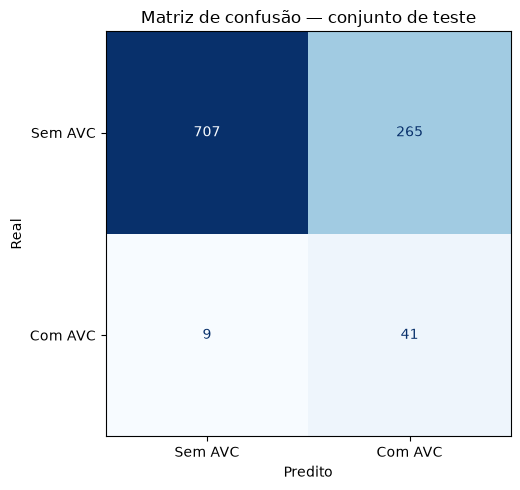

Verdadeiros negativos: 707
Falsos positivos:      265  (pacientes sem AVC sinalizados como risco)
Falsos negativos:      9  (casos de AVC que o modelo deixou passar)
Verdadeiros positivos: 41


In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sem AVC", "Com AVC"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Matriz de confusão — conjunto de teste")
ax.set_xlabel("Predito")
ax.set_ylabel("Real")

plt.tight_layout()
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()

print(f"Verdadeiros negativos: {vn}")
print(f"Falsos positivos:      {fp}  (pacientes sem AVC sinalizados como risco)")
print(f"Falsos negativos:      {fn}  (casos de AVC que o modelo deixou passar)")
print(f"Verdadeiros positivos: {vp}")

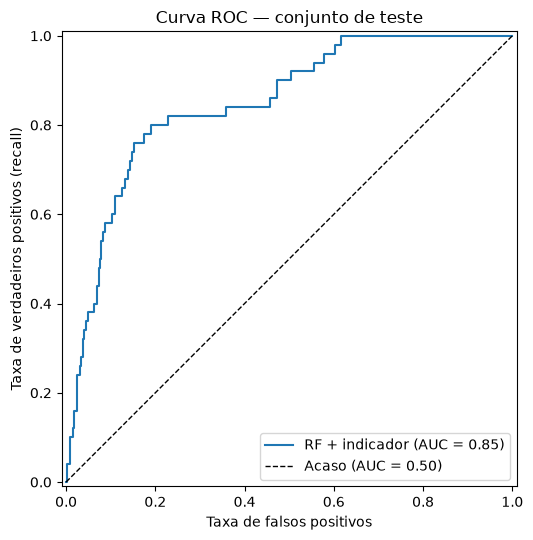

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

RocCurveDisplay.from_predictions(y_test, y_proba, name="RF + indicador", ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Acaso (AUC = 0.50)")
ax.set_title("Curva ROC — conjunto de teste")
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.legend()

plt.tight_layout()
plt.show()

### Leitura dos resultados no teste

| Métrica | Valor |
|---|---:|
| Accuracy | 0,732 |
| Precision (classe AVC) | 0,134 |
| Recall (classe AVC) | 0,820 |
| F1-score (classe AVC) | 0,230 |
| ROC-AUC | 0,849 |
| PR-AUC | 0,232 |

Matriz de confusão: **41 dos 50** casos de AVC foram detectados, **9 passaram
despercebidos** e **265 pacientes sem AVC** foram sinalizados sem necessidade.

**A accuracy de 0,732 é pior que a do modelo trivial, e isso é intencional.**
Prever "sem AVC" para todo mundo daria 0,951. O `class_weight="balanced"` faz o
modelo trocar accuracy por recall. Nesse problema é a troca certa: um falso
positivo custa um exame a mais; um falso negativo, um AVC não prevenido.

**A distância entre ROC-AUC (0,849) e PR-AUC (0,232) é a razão de termos
escolhido a PR-AUC.** Na curva ROC, o limiar de 0,5 vira um ponto com recall de
0,82 e taxa de falsos positivos de 0,27 (265 de 972 negativos), que parece
razoável. Na precision, os mesmos 265 falsos positivos são comparados com apenas
41 acertos, e ela cai para 0,134: de cada 7 ou 8 pacientes sinalizados, só um
teve AVC. Reportar só o ROC-AUC passaria a impressão de um modelo muito melhor
do que ele é.

**O limiar de 0,5 não é obrigatório.** Todos esses números vêm do corte padrão.
Deslocá-lo move o modelo ao longo da curva precision-recall sem retreinar nada,
e a escolha do ponto deveria vir do custo relativo entre exame desnecessário e
AVC não prevenido, uma decisão clínica e não estatística [7].

---

## 3. Interpretação e explicabilidade

### 3.1 Modelo linear: os 3 coeficientes de maior magnitude

Usamos a regressão logística ajustada na Seção 1.2. Como as variáveis numéricas
foram padronizadas e as categóricas estão em 0/1, os coeficientes são
comparáveis entre si. Eles estão em escala de log-odds: nas numéricas, um
coeficiente de 1,88 significa que um desvio padrão a mais na variável multiplica
as chances de AVC por `exp(1,88)` (o *odds ratio*); nas binárias, a mesma conta
vale para a passagem de 0 para 1.

,coeficiente,odds ratio
age,1.877,6.536
work_type_children,0.862,2.368
hypertension,0.585,1.795


Desvio padrão de age no treino: 22.6 anos


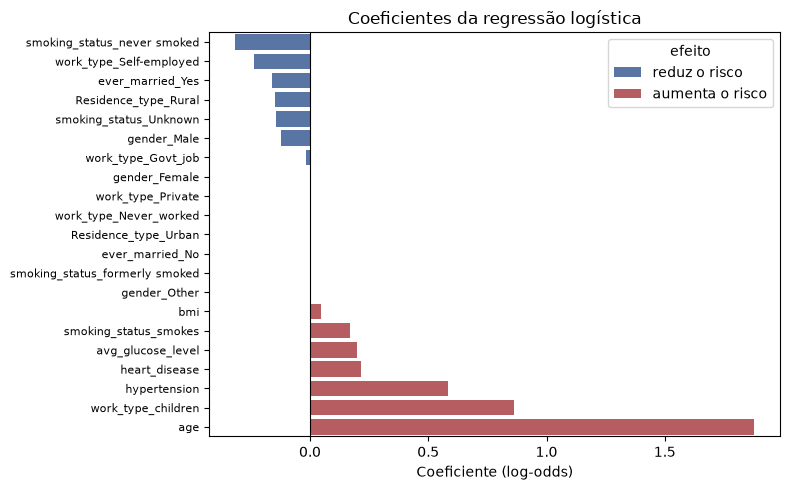

In [14]:
modelo_linear = busca_logistica.best_estimator_

coeficientes = pd.DataFrame(
    {"coeficiente": modelo_linear[-1].coef_[0]},
    index=modelo_linear[:-1].get_feature_names_out(),
)
coeficientes["odds ratio"] = np.exp(coeficientes["coeficiente"])

display(coeficientes.sort_values("coeficiente", key=abs, ascending=False).head(3).round(3))
desvio_idade = modelo_linear[0].named_transformers_["numericas"]["scaler"].scale_[0]
print(f"Desvio padrão de age no treino: {desvio_idade:.1f} anos")

ordenados = coeficientes.sort_values("coeficiente").assign(
    efeito=lambda d: np.where(d["coeficiente"] > 0, "aumenta o risco", "reduz o risco")
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=ordenados,
    x="coeficiente",
    y=ordenados.index,
    hue="efeito",
    palette={"aumenta o risco": "#C44E52", "reduz o risco": "#4C72B0"},
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (log-odds)")
ax.set_ylabel("")
ax.set_title("Coeficientes da regressão logística")
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Análise das 3 maiores magnitudes:**

**1. `age` (coeficiente +1,88, odds ratio 6,5).** Domina o modelo com folga: é
mais que o dobro do segundo colocado. Cada desvio padrão de idade (22,6
anos) multiplica por 6,5 as chances de AVC. Bate com a literatura médica e com o
que a APS1 já mostrava nos boxplots.

**2. `work_type_children` (coeficiente +0,86).** Esse coeficiente **não deve ser
lido como causal**. Crianças praticamente não têm AVC na base; o coeficiente
positivo aparece porque o modelo já aplicou uma penalidade enorme via `age`
(crianças têm idade muito baixa), e esse termo funciona como uma correção
parcial dela. É efeito da colinearidade entre `work_type` e `age`, não um achado
clínico.

**3. `hypertension` (coeficiente +0,59, odds ratio 1,8).** Hipertensão quase
dobra as chances de AVC, mantidas as demais variáveis. Aqui temos um fator de
risco clínico bem estabelecido, recuperado com o sinal e a ordem de grandeza
corretos.

### 3.2 Modelo ensemble: as 3 features de maior importância

Usamos a Random Forest ajustada na Seção 1.2, sem o indicador de ausência, para
compará-la com a regressão logística sobre as mesmas features. O melhor modelo
final, com o indicador, é interpretado com SHAP na Seção 3.3. A importância mede quanto cada feature reduziu a impureza dos nós, somado sobre
todas as árvores.

,importância
age,0.6429
avg_glucose_level,0.1107
bmi,0.0930


hypertension: 0.021 (6º lugar)


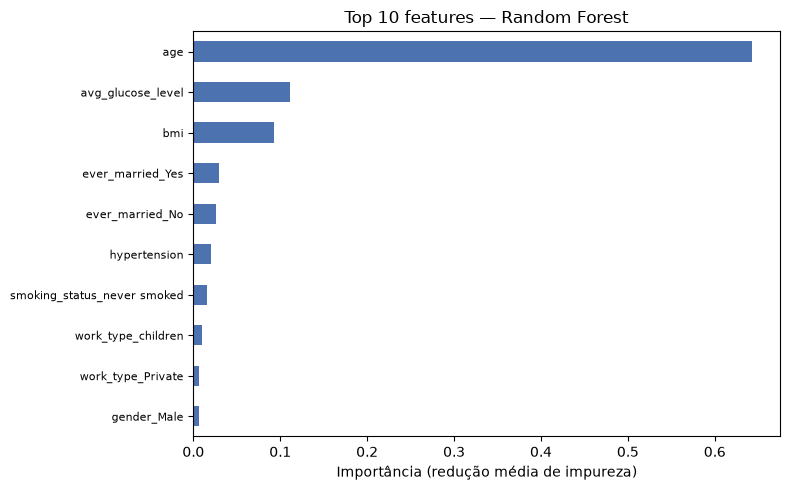

In [15]:
modelo_ensemble = busca_floresta.best_estimator_

importancias = pd.Series(
    modelo_ensemble[-1].feature_importances_,
    index=modelo_ensemble[:-1].get_feature_names_out(),
    name="importância",
).sort_values(ascending=False)

display(importancias.head(3).round(4).to_frame())
posicao = importancias.index.get_loc("hypertension") + 1
print(f"hypertension: {importancias['hypertension']:.3f} ({posicao}º lugar)")

fig, ax = plt.subplots(figsize=(8, 5))
importancias.head(10).sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Importância (redução média de impureza)")
ax.set_title("Top 10 features — Random Forest")
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Análise das 3 maiores importâncias:**

**1. `age` (0,643).** Sozinha responde por quase dois terços da importância
total. Os dois modelos, com mecanismos completamente diferentes, concordam que
idade é o preditor dominante, o que aumenta a confiança no achado.

**2. `avg_glucose_level` (0,111).** Glicose média aparece em segundo. Faz sentido
clínico (diabetes é fator de risco para AVC), lembrando que a APS1 mostrou uma
distribuição bimodal, com cauda longa de valores altos.

**3. `bmi` (0,093).** IMC em terceiro.

**Uma armadilha:** as três features mais importantes são exatamente as três
variáveis **numéricas contínuas**. Não é coincidência: a importância por
impureza é **enviesada a favor de variáveis com muitos valores distintos**,
porque elas oferecem mais pontos de corte e acabam escolhidas mais vezes [8].
As variáveis binárias ficam em desvantagem estrutural.

Na regressão logística, `hypertension` era o terceiro coeficiente mais forte;
aqui fica em 6º lugar, com importância de apenas 0,021. Parte dessa divergência
pode vir do viés, e a próxima seção confere com SHAP, que não depende da
contagem de cortes.

### 3.3 SHAP: importância global e explicação de predições individuais

Os valores SHAP vêm da teoria dos jogos cooperativos: distribuem a diferença
entre a predição e o valor médio entre as features [2]. Em vez de somar a redução
de impureza de cada corte, medem quanto cada feature desloca a predição, o que
evita o viés de medição da seção anterior. Também permitem explicar **uma
predição individual**, não só a média.

O explainer trabalha sobre a matriz já pré-processada, porque é ela que o
classificador enxerga. O valor base sai perto de 0,50, e não da prevalência de
4,87%, por causa do `class_weight="balanced"`: o peso extra dos positivos faz a
floresta enxergar classes equilibradas. Por isso as "probabilidades" deste
modelo servem para ordenar pacientes, mas não devem ser lidas como risco
absoluto.

In [16]:
import shap

X_test_proc = melhor_modelo[:-1].transform(X_test)
nomes = melhor_modelo[:-1].get_feature_names_out()

explainer = shap.TreeExplainer(melhor_modelo[-1])
# para RandomForestClassifier o SHAP devolve (amostras, features, classes); ficamos com a classe AVC
shap_avc = explainer.shap_values(X_test_proc)[:, :, 1]
valor_base = explainer.expected_value[1]

print("Formato dos valores SHAP:", shap_avc.shape)
print(f"Valor base (predição média): {valor_base:.4f}")

Formato dos valores SHAP: (1022, 22)
Valor base (predição média): 0.4999


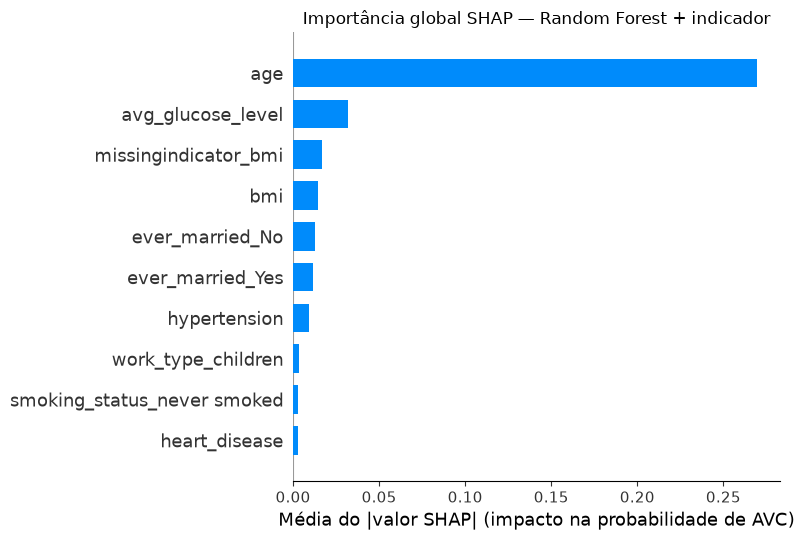

,SHAP médio absoluto
age,0.2694
avg_glucose_level,0.0317
missingindicator_bmi,0.0168
bmi,0.0146
ever_married_No,0.0129
ever_married_Yes,0.0114
hypertension,0.0093


In [17]:
shap.summary_plot(
    shap_avc,
    X_test_proc,
    feature_names=nomes,
    plot_type="bar",
    max_display=10,
    show=False,
)
plt.title("Importância global SHAP — Random Forest + indicador")
plt.xlabel("Média do |valor SHAP| (impacto na probabilidade de AVC)")
plt.tight_layout()
plt.show()

shap_medio = pd.Series(np.abs(shap_avc).mean(axis=0), index=nomes).sort_values(ascending=False)
display(shap_medio.head(7).round(4).to_frame("SHAP médio absoluto"))

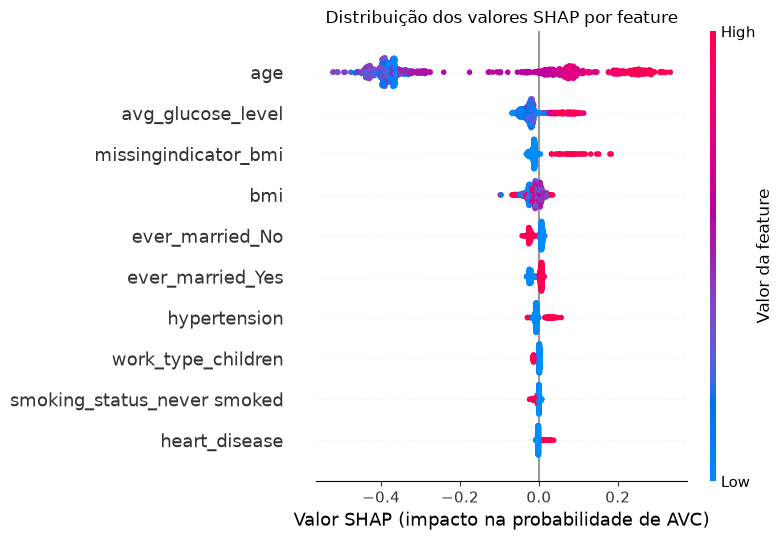

In [18]:
shap.summary_plot(
    shap_avc,
    X_test_proc,
    feature_names=nomes,
    max_display=10,
    show=False,
)
plt.title("Distribuição dos valores SHAP por feature")
plt.xlabel("Valor SHAP (impacto na probabilidade de AVC)")
plt.gcf().axes[-1].set_ylabel("Valor da feature")
plt.tight_layout()
plt.show()

#### Importância global

| Feature | SHAP médio absoluto |
|---|---:|
| `age` | 0,2694 |
| `avg_glucose_level` | 0,0317 |
| `missingindicator_bmi` | 0,0168 |
| `bmi` | 0,0146 |
| `ever_married_No` | 0,0129 |
| `ever_married_Yes` | 0,0114 |
| `hypertension` | 0,0093 |

A concentração em `age` fica ainda mais evidente: ela pesa **8,5 vezes** mais que
a segunda colocada. No beeswarm, valores altos de idade (vermelho) ficam todos
do lado positivo, ou seja, a relação aprendida é monotônica, como esperado.

A novidade em relação à Seção 3.2 é o **`missingindicator_bmi`**, que só existe
neste modelo: ele aparece em terceiro, um pouco à frente do próprio `bmi`
(0,0168 contra 0,0146). Para o modelo, saber que o IMC não foi medido vale tanto
quanto o valor do IMC, o que é o retrato quantitativo do ganho da Seção 1.3.

`hypertension` continua lá embaixo (7º lugar, 0,0093), então o viés da
importância por impureza não explica sozinho a divergência com a regressão
logística. Uma leitura plausível é que a floresta, por conseguir modelar a idade
de forma não linear, extrai dela boa parte do sinal que a logística atribui à
hipertensão, já que as duas andam juntas.

#### Explicação de 3 predições individuais

Escolhemos três pacientes que representam situações distintas, pegando em cada
grupo o caso de maior probabilidade predita:

1. um **verdadeiro positivo**: o caso em que o modelo tem mais certeza;
2. um **falso negativo**: um AVC real que passou despercebido;
3. um **falso positivo**: um alarme falso confiante.

In [19]:
y_real = y_test.to_numpy()

grupos = {
    "Verdadeiro positivo (maior confiança)": (y_real == 1) & (y_pred == 1),
    "Falso negativo (AVC não detectado)": (y_real == 1) & (y_pred == 0),
    "Falso positivo (alarme falso confiante)": (y_real == 0) & (y_pred == 1),
}
casos = {titulo: np.flatnonzero(m)[y_proba[m].argmax()] for titulo, m in grupos.items()}

for titulo, i in casos.items():
    contribuicoes = pd.Series(shap_avc[i], index=nomes)
    principais = contribuicoes.sort_values(key=abs, ascending=False).head(3)

    print(f"{titulo}\nProbabilidade predita: {y_proba[i]:.3f} | Classe real: {y_real[i]}\n")
    print(X_test.iloc[i].to_string())
    print("\n3 features que mais contribuíram:")
    print(principais.round(4).to_string())
    print("=" * 60)

Verdadeiro positivo (maior confiança)
Probabilidade predita: 0.861 | Classe real: 1

gender                  Male
age                     78.0
hypertension               0
heart_disease              1
ever_married             Yes
work_type            Private
Residence_type         Urban
avg_glucose_level     219.84
bmi                      NaN
smoking_status       Unknown

3 features que mais contribuíram:
age                     0.2261
missingindicator_bmi    0.0848
avg_glucose_level       0.0205
Falso negativo (AVC não detectado)
Probabilidade predita: 0.454 | Classe real: 1

gender                  Male
age                     59.0
hypertension               0
heart_disease              0
ever_married             Yes
work_type            Private
Residence_type         Rural
avg_glucose_level      96.16
bmi                     44.1
smoking_status       Unknown

3 features que mais contribuíram:
age                  0.0896
avg_glucose_level   -0.0568
bmi                 -0.0459
Falso 

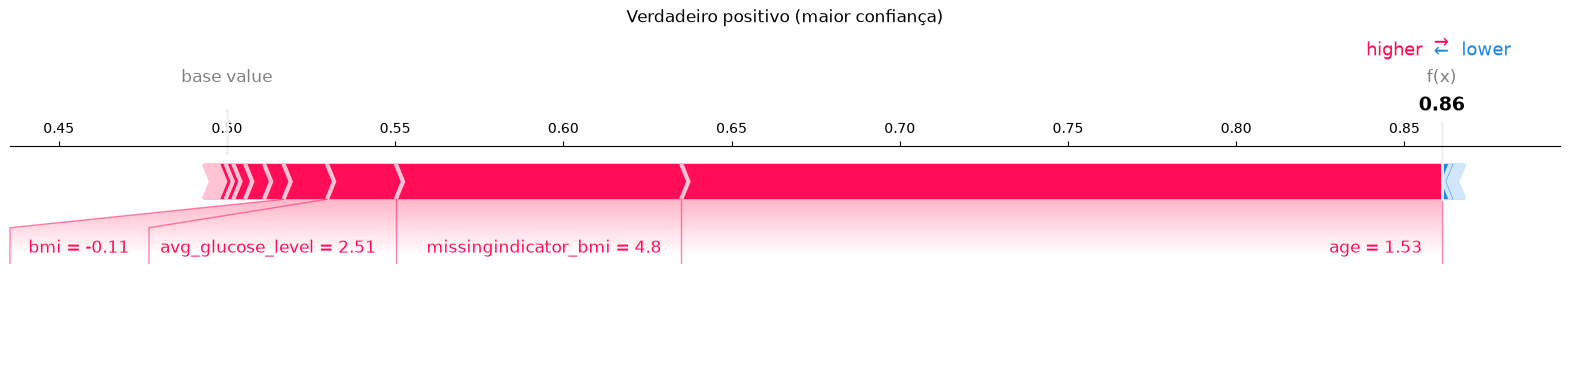

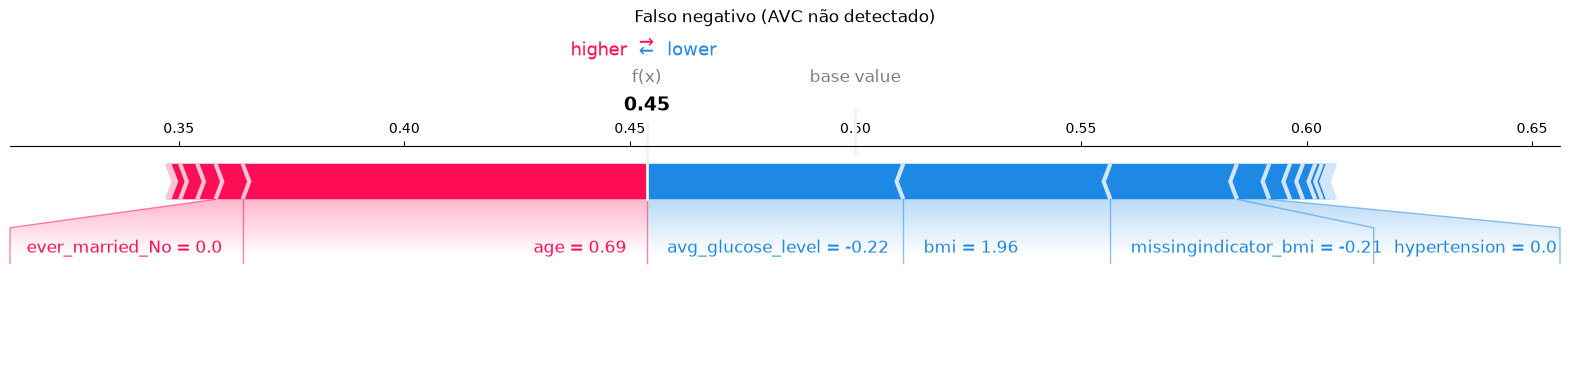

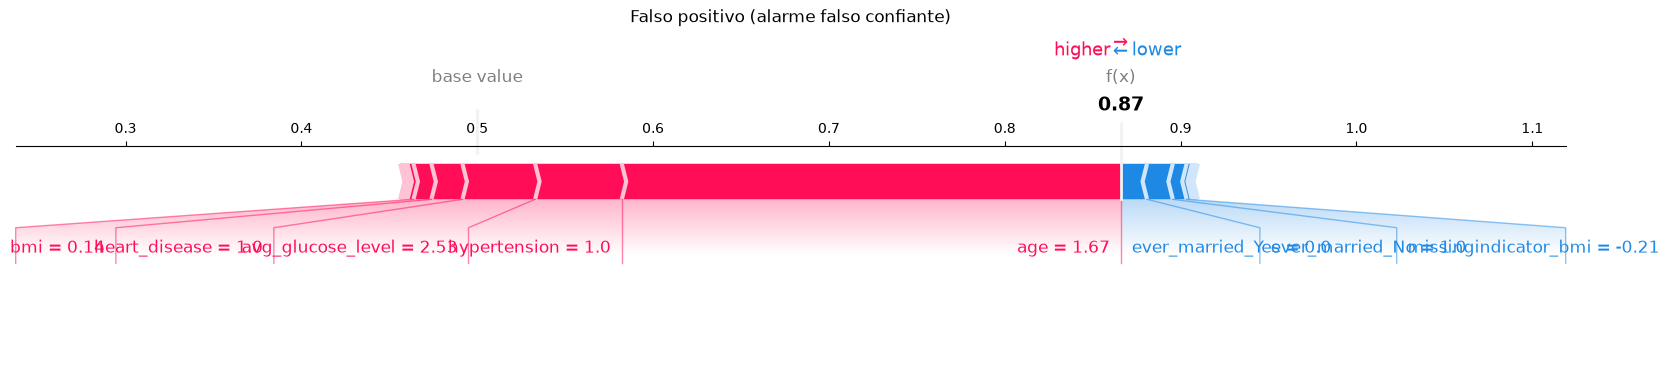

In [20]:
for titulo, i in casos.items():
    # matplotlib=True gera figura estática, que fica salva nos outputs do notebook
    shap.force_plot(
        valor_base,
        shap_avc[i],
        features=X_test_proc[i].round(2),
        feature_names=nomes,
        matplotlib=True,
        show=False,
    )
    plt.title(titulo, y=1.5)
    plt.show()

#### Análise das explicações individuais

Nos force plots, os valores das features estão na escala padronizada (o que o
modelo enxerga); os valores originais estão na saída da célula anterior. O
indicador de ausência também passa pelo `StandardScaler`, por isso aparece como
4,8 quando o IMC falta e −0,21 quando está presente.

**1. Verdadeiro positivo: homem, 78 anos, doença cardíaca, glicose 219,8,
`bmi` ausente. Probabilidade predita: 0,861.**

| Feature | Contribuição SHAP |
|---|---:|
| `age` | +0,2261 |
| `missingindicator_bmi` | +0,0848 |
| `avg_glucose_level` | +0,0205 |

A segunda maior contribuição **não é um fator clínico**, e sim o fato de o IMC
não ter sido registrado. O indicador de ausência pesa quatro vezes mais que uma
glicose de 219,8 mg/dL, valor altíssimo, e a doença cardíaca diagnosticada nem
aparece no top 3.

**2. Falso negativo: homem, 59 anos, sem hipertensão, sem doença cardíaca,
glicose 96,2, IMC 44,1. Probabilidade predita: 0,454 (escapou por 0,046).**

| Feature | Contribuição SHAP |
|---|---:|
| `age` | +0,0896 |
| `avg_glucose_level` | −0,0568 |
| `bmi` | −0,0459 |

O modelo quase acertou. A idade empurrou para cima (+0,090), mas a glicose
normal (96,2) e o IMC puxaram para baixo com força somada um pouco maior
(−0,103), e foi isso que deixou a probabilidade abaixo do limiar.

Chama atenção que um IMC de 44,1 (obesidade grave) tenha **reduzido** o risco
predito. Isso contraria o senso clínico e indica que o modelo não aprendeu uma
relação confiável para `bmi`, provavelmente porque a cauda alta da distribuição
tem poucos exemplos com AVC.

**3. Falso positivo: homem, 81 anos, hipertensão, doença cardíaca, glicose
220,6, IMC 30,0. Probabilidade predita: 0,866.**

| Feature | Contribuição SHAP |
|---|---:|
| `age` | +0,2839 |
| `hypertension` | +0,0493 |
| `avg_glucose_level` | +0,0413 |

Aqui o erro é razoável: o paciente acumula idade avançada, hipertensão, doença
cardíaca e glicose de 220,6, os fatores de risco clássicos na ordem
clinicamente esperada. O AVC simplesmente não aconteceu. Para uma ferramenta de
triagem, encaminhar esse paciente seria uma decisão defensável mesmo conhecendo
o desfecho, ao contrário do falso negativo do caso 2.

**Comparando os três.** `age` é a maior contribuição nos três casos e, nos dois
de alta confiança, é 2,7 e 5,8 vezes maior que a segunda colocada. Os demais fatores
ajustam a margem da decisão.

---

## 4. Discussão crítica

### 4.1 Duas limitações do melhor modelo

**(1) O ganho do indicador de ausência pode não transferir para outro hospital.**

O maior ganho de desempenho do trabalho (+21% de PR-AUC) veio do
`missingindicator_bmi`, que é a terceira feature mais influente no SHAP e a
segunda contribuição no caso 1 da Seção 3.3. Mas "o IMC não foi registrado" não
é um fator de risco: é um reflexo de como estes dados foram coletados. Em outro
hospital, com outro protocolo de registro, essa coluna significaria outra coisa
ou nada. Pior: se o hospital passar a registrar o IMC de todo mundo, o
desempenho cai sem que nada tenha mudado nos pacientes. É um caso de *dataset
shift* bem documentado na literatura de IA clínica [3].

**(2) Na prática, o modelo é em grande parte um detector de idade.**

`age` tem SHAP médio 8,5 vezes maior que a segunda feature do melhor modelo.
Isso levanta a questão de qual é o ganho real sobre uma regra simples como
"encaminhe todo paciente com 60 anos ou mais". Para responder, cruzamos as
predições do conjunto de teste com a idade e comparamos com essa regra. É uma
análise feita depois da escolha do modelo, que não altera nenhuma decisão
anterior. A dominância da idade em si é coerente com a epidemiologia do AVC, em
que ela é o fator de risco de maior peso populacional [4].


In [21]:
faixa = np.where(X_test["age"] < 60, "menos de 60 anos", "60 anos ou mais")

por_faixa = (
    pd.DataFrame({"faixa": faixa, "avc": y_real, "detectado": (y_real == 1) & (y_pred == 1)})
    .groupby("faixa")
    .agg(pacientes=("avc", "size"), casos_avc=("avc", "sum"), detectados=("detectado", "sum"))
)
display(por_faixa)

regra_idade = (X_test["age"] >= 60).astype(int)
contra_regra = pd.DataFrame(
    {
        "Recall": [recall_score(y_test, y_pred), recall_score(y_test, regra_idade)],
        "Precision": [precision_score(y_test, y_pred), precision_score(y_test, regra_idade)],
        "sinalizados": [y_pred.sum(), regra_idade.sum()],
    },
    index=["RF + indicador (limiar 0,5)", "regra: 60 anos ou mais"],
)
display(contra_regra.round(3))

# a idade crua também é um escore: dá para calcular a PR-AUC dela sem modelo nenhum
print(f"PR-AUC da idade sozinha: {average_precision_score(y_test, X_test['age']):.4f}")
print(f"PR-AUC do modelo:        {average_precision_score(y_test, y_proba):.4f}")


,pacientes,casos_avc,detectados
faixa,,,
60 anos ou mais,272,38,38
menos de 60 anos,750,12,3


,Recall,Precision,sinalizados
"RF + indicador (limiar 0,5)",0.82,0.134,306
regra: 60 anos ou mais,0.76,0.140,272


PR-AUC da idade sozinha: 0.1969
PR-AUC do modelo:        0.2317


**O que a análise mostra.** O modelo detecta os 38 casos de AVC com 60 anos ou
mais e só 3 dos 12 casos abaixo dessa idade. Contra a regra de idade, ele ganha
6 pontos de recall (0,82 contra 0,76) ao custo de 34 encaminhamentos a mais e
precision ligeiramente menor. Usada como escore, a idade sozinha já tem PR-AUC
de 0,197, contra 0,232 do modelo. Ou seja, boa parte do desempenho vem de
ordenar pacientes por idade, e os pacientes mais jovens com AVC, que seriam os
mais beneficiados por uma triagem automatizada (o médico dificilmente
suspeitaria deles), são justamente os que o modelo perde. **O valor clínico fica
concentrado onde o modelo é mais fraco.** Com só 12 casos abaixo de 60 anos no
teste, as proporções exatas são frágeis; a direção da diferença, porém, é
nítida.

### 4.2 Duas limitações dos dados

**(1) O dataset não tem dimensão temporal.**

Cada linha é uma fotografia: as features e o `stroke` estão no mesmo instante.
Não sabemos se a hipertensão foi diagnosticada antes ou depois do AVC, nem se a
glicose foi medida na internação causada pelo próprio AVC. Isso inviabiliza
afirmações causais e abre espaço para **vazamento temporal**: parte do que o
modelo usa como "preditor" pode ser consequência do desfecho [5]. Um modelo de
predição de risco precisaria de features medidas comprovadamente *antes* do
evento.

**(2) Faltam fatores de risco conhecidos, e os que existem são grosseiros.**

A base não traz colesterol, função renal, fibrilação atrial, AVC ou ataque
isquêmico transitório anteriores, nem a medicação em uso. Vários desses fatores
aparecem na literatura como determinantes importantes do AVC [4]. As variáveis
presentes são resumos: `hypertension` e `heart_disease` são apenas sim/não, sem
gravidade nem controle; `smoking_status` não registra intensidade; e o próprio
`stroke` não distingue AVC isquêmico de hemorrágico, que têm perfis de risco
diferentes. Isso impõe um teto ao desempenho que nenhum ajuste de modelo
ultrapassa e ajuda a explicar por que a idade, única variável contínua com
relação forte com o desfecho, domina as interpretações da Seção 3.

### 4.3 Duas ações para operacionalização e manutenção

**(1) Monitorar a distribuição das entradas, não só o desempenho.**

O desfecho de AVC leva meses ou anos para ser observado, então esperar pelos
rótulos para descobrir que o modelo degradou é descobrir tarde demais. A ação
concreta é registrar, a cada lote de predições, a distribuição das features de
entrada e compará-la com a do treino, com atenção especial à **taxa de ausência
do `bmi`**, pela dependência descrita em 4.1. Um alarme quando essa taxa se afastar da
observada no treino (4,2%, 170 de 4.088 pacientes) detectaria o problema sem
precisar de um único rótulo novo. Monitorar as entradas é recomendação central
tanto da literatura de dataset shift em saúde [3] quanto da de manutenção de
sistemas de ML em produção [6].

**(2) Separar a escolha do limiar do treinamento e revisá-la periodicamente.**

Hoje usamos o limiar padrão de 0,5, que não tem justificativa clínica. O limiar
deveria ser um parâmetro de configuração definido pela equipe médica a partir da
capacidade de atendimento: quantos encaminhamentos por mês o serviço comporta
define onde cortar na curva precision-recall. Mantido fora do modelo, ele pode
ser recalibrado quando a capacidade mudar, sem retreinar nada. Com uma revisão
semestral usando dados novos rotulados, o sistema se mantém útil sem
reimplantação completa a cada ajuste. A separação entre o modelo, que estima
probabilidades, e o limiar, que reflete custos e capacidade, segue a análise
custo-sensível de Provost e Fawcett [7].

---

## 5. Referências bibliográficas

[1] RUBIN, D. B. Inference and Missing Data. *Biometrika*, v. 63, n. 3, p. 581-592, 1976.

[2] LUNDBERG, S. M.; LEE, S.-I. A Unified Approach to Interpreting Model Predictions. In: *Advances in Neural Information Processing Systems (NeurIPS)*, v. 30, 2017.

[3] FINLAYSON, S. G. et al. The Clinician and Dataset Shift in Artificial Intelligence. *New England Journal of Medicine*, v. 385, n. 3, p. 283-286, 2021.

[4] GBD 2019 STROKE COLLABORATORS. Global, Regional, and National Burden of Stroke and Its Risk Factors, 1990-2019: A Systematic Analysis for the Global Burden of Disease Study 2019. *The Lancet Neurology*, v. 20, n. 10, p. 795-820, 2021.

[5] KAUFMAN, S.; ROSSET, S.; PERLICH, C. Leakage in Data Mining: Formulation, Detection, and Avoidance. *ACM Transactions on Knowledge Discovery from Data*, v. 6, n. 4, p. 1-21, 2012.

[6] SCULLEY, D. et al. Hidden Technical Debt in Machine Learning Systems. In: *Advances in Neural Information Processing Systems (NeurIPS)*, v. 28, 2015.

[7] PROVOST, F.; FAWCETT, T. *Data Science for Business*. Sebastopol: O'Reilly Media, 2013.

[8] STROBL, C. et al. Bias in Random Forest Variable Importance Measures: Illustrations, Sources and a Solution. *BMC Bioinformatics*, v. 8, n. 25, 2007.